# Interference and Advanced Designs: Switchbacks, Clusters, Marketplaces

**What you'll learn**

- What SUTVA actually buys you, the three interference patterns that break it in
  industry (marketplaces, social networks, shared resources), and why the *estimand*
  — the global treatment effect of launching to everyone — is what the business pays for.
- A two-sided marketplace simulator with shared, finite supply, used to *measure* how
  badly a naive user-split A/B overstates the true launch effect — and how the bias
  grows as supply tightens.
- Switchback experiments end-to-end: randomization period length, balanced schedules,
  burn-in for carryover, regression analysis with time fixed effects, and block
  bootstrap standard errors — validated against the simulator's ground truth.
- Cluster (geo) randomization: when it removes interference bias, what it costs in
  power, and cluster-level analysis with paired assignment.
- Network experiments on a synthetic social graph: community-based cluster
  randomization and the exposure-fraction idea, with Louvain community detection.
- Interleaving for ranking evaluation: why within-query comparison is an order of
  magnitude more sensitive than an A/B on the same traffic — and what it cannot tell you.

**Why it matters in interviews**

- "How would you test a driver-pricing change?" is *the* marketplace-company screen
  (Uber, Lyft, DoorDash, Instacart, Airbnb). The expected answer is "not a user-split
  A/B", followed by a coherent switchback or geo design.
- "How do you experiment on a social feed?" probes whether you know that spillovers make
  the naive difference-in-means estimate the *direct* effect only, and that graph-cluster
  designs recover (most of) the total effect.
- Senior candidates are expected to name the estimand (global/total treatment effect vs
  the naive contrast), quantify the bias direction, and push back constructively when a
  PM asks to "just run a normal A/B".

Prerequisites from siblings: experiment mechanics in
[01_ab_test_end_to_end.ipynb](./01_ab_test_end_to_end.ipynb), ICC and the design effect
in [02_power_mde_sample_size.ipynb](./02_power_mde_sample_size.ipynb) (section 6), and
cluster-robust analysis of ratio metrics in
[05_ratio_metrics_delta_method.ipynb](./05_ratio_metrics_delta_method.ipynb). We reuse
those results rather than re-deriving them.

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
import networkx as nx

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "figure.constrained_layout.use": True,
})
pd.set_option("display.width", 130)

## 1. SUTVA and interference: what breaks, where

Every standard A/B analysis rests on the **Stable Unit Treatment Value Assumption**:
unit $i$'s outcome depends only on unit $i$'s own assignment,
$Y_i(z_1,\dots,z_n) = Y_i(z_i)$. That is what licenses "difference in means between
arms estimates the average treatment effect". When SUTVA fails, the experiment still
*runs* — randomization still balances covariates, the dashboard still fills in — but the
contrast you compute no longer estimates the thing you will get at launch.

Name the estimand first. What the business buys is the **global treatment effect (GTE)**:

$$\text{GTE} \;=\; \bar{Y}(\text{everyone treated}) \;-\; \bar{Y}(\text{no one treated}),$$

a contrast between two *worlds*. A 50/50 user split instead compares treated and control
units **inside a single mixed world**, and under interference that mixed world is a
different place than either counterfactual.

Three patterns cover most industry cases:

| Pattern | Mechanism | Typical bias of naive user-split | Examples |
|---|---|---|---|
| **Marketplace / shared supply** | Treated units draw from a finite common pool (drivers, inventory, ad slots), so treatment *cannibalizes* control | **Overstates** the GTE (control is starved, gap widens) | Ride-hailing pricing, delivery promos, hotel ranking |
| **Network spillovers** | Treatment leaks across edges: treated friends make control users more (or less) active | **Understates** a positive total effect (control is partially treated) | Social feeds, messaging features, referral programs |
| **Shared resources / feedback loops** | Arms share a budget, a cache, a ranking model retrained on pooled data, or a fraud-attacker population | Either direction; often subtle | Ads pacing, recommender feedback, spam/fraud counter-adaptation |

The two big failure directions are worth memorizing: **competition inflates** the naive
estimate, **contagion deflates** it. The rest of this notebook makes that quantitative.

## 2. A two-sided marketplace simulator

We build a small ride-hailing-style market and use it as ground truth for everything
that follows. The design goal is the minimal structure that produces real interference:

- **Riders** (demand): `n_riders = 2,000` active users; each hour, each rider requests a
  ride with probability `p_req` scaled by an hour-of-day demand curve (commute peaks).
- **Drivers** (supply): capacity of `n_drivers` scaled by an hour-of-day supply curve —
  supply follows demand only partially, so **peak hours are supply-constrained**.
- **Matching**: if requests exceed capacity in an hour, available rides are rationed
  uniformly at random among requesters (treated and control compete in the same queue).
- **Carryover**: unserved requesters retry the next hour with probability `retry_prob`
  — this is the state that will make switchback carryover real.
- **Treatment**: a demand-side incentive (say, a coupon) that lifts a treated rider's
  request probability by **+25%**. The *demand-side* effect is exactly +25% by
  construction; the question is what happens to *completed rides*.

Because we only need counts, each hour is a handful of draws: binomial arrivals per arm,
a capacity cap, and a **hypergeometric** split of served rides between arms (that *is*
uniform rationing). This keeps the simulator exact and fast enough to replicate. The
`n_rep` axis vectorizes independent replicates — or, later, independent *cities*.

In [2]:
HOURS = np.arange(24)
# Demand: night trough, morning and evening commute peaks.
HOUR_MULT = (0.35
             + 0.90 * np.exp(-0.5 * ((HOURS - 8) / 2.2) ** 2)
             + 1.15 * np.exp(-0.5 * ((HOURS - 18) / 2.6) ** 2))
# Supply follows demand, but only partially -> peaks are the tight hours.
SUPPLY_MULT = 0.60 + 0.40 * HOUR_MULT / HOUR_MULT.max()


def run_market(treat_type, n_days=42, n_rep=100, n_riders=2000, n_drivers=170,
               p_req=0.06, lift=0.25, retry_prob=0.6, schedule=None,
               split_frac=0.5, cluster_treated=None, rng=None):
    """Hour-by-hour two-sided market with shared supply, vectorized over replicates.

    treat_type: 'global_off' | 'global_on' | 'user_split' | 'switchback' | 'cluster'
      - user_split: split_frac of riders permanently treated (naive A/B)
      - switchback: `schedule` (bool, n_hours) says which hours the whole market is treated
      - cluster:    `cluster_treated` (bool, n_rep) treats entire replicates ("cities");
                    n_riders / n_drivers may be arrays of shape (n_rep,)
    Returns dict of (n_hours, n_rep) arrays: served/requests by arm, plus pool sizes.
    """
    n_hours = 24 * n_days
    hod = np.arange(n_hours) % 24
    lam = p_req * HOUR_MULT[hod]                                  # (n_hours,)
    riders = np.broadcast_to(np.asarray(n_riders), (n_rep,))
    cap = np.rint(np.multiply.outer(SUPPLY_MULT[hod],
                                    np.broadcast_to(np.asarray(n_drivers), (n_rep,)))
                  ).astype(np.int64)                              # (n_hours, n_rep)

    if treat_type == "global_off":
        nT = np.zeros((n_hours, n_rep), dtype=np.int64)
    elif treat_type == "global_on":
        nT = np.broadcast_to(riders, (n_hours, n_rep)).copy()
    elif treat_type == "user_split":
        nT = np.broadcast_to(np.rint(riders * split_frac).astype(np.int64),
                             (n_hours, n_rep)).copy()
    elif treat_type == "switchback":
        nT = np.where(schedule[:, None], riders[None, :], 0)
    elif treat_type == "cluster":
        nT = np.broadcast_to(np.where(cluster_treated, riders, 0), (n_hours, n_rep)).copy()
    else:
        raise ValueError(treat_type)
    nC = riders[None, :] - nT

    p_treat = np.minimum(lam * (1 + lift), 1.0)
    qT = np.zeros(n_rep, dtype=np.int64)
    qC = np.zeros(n_rep, dtype=np.int64)
    out = {k: np.zeros((n_hours, n_rep), dtype=np.int64)
           for k in ["served_T", "served_C", "req_T", "req_C"]}
    for t in range(n_hours):
        new_T = rng.binomial(nT[t], p_treat[t])
        new_C = rng.binomial(nC[t], lam[t])
        RT, RC = new_T + qT, new_C + qC
        R = RT + RC
        s = np.minimum(R, cap[t])
        sT = rng.hypergeometric(RT, RC + (R == 0), s)   # uniform rationing across arms
        sC = s - sT
        qT = rng.binomial(RT - sT, retry_prob)          # unserved retry next hour
        qC = rng.binomial(RC - sC, retry_prob)
        out["served_T"][t], out["served_C"][t] = sT, sC
        out["req_T"][t], out["req_C"][t] = RT, RC
    out["n_T"], out["n_C"], out["riders"] = nT, nC, riders
    return out

### Ground truth: the global treatment effect

The GTE is a two-worlds contrast, so we simulate both worlds: every rider treated vs no
rider treated, 100 independent replicates each. The metric is **completed rides per
rider over the horizon** (a per-user conversion-style metric).

In [3]:
N_DAYS, N_REP = 42, 100

world_off = run_market("global_off", n_days=N_DAYS, n_rep=N_REP, rng=rng)
world_on = run_market("global_on", n_days=N_DAYS, n_rep=N_REP, rng=rng)

def rides_per_rider(w):
    """Completed rides per rider over the whole horizon, one value per replicate."""
    return (w["served_T"] + w["served_C"]).sum(axis=0) / w["riders"]

rpr_off, rpr_on = rides_per_rider(world_off), rides_per_rider(world_on)
GTE_REL = rpr_on.mean() / rpr_off.mean() - 1

fill_off = (world_off["served_C"].sum() / world_off["req_C"].sum())
fill_on = (world_on["served_T"].sum() / world_on["req_T"].sum())
print(f"Rides/rider, all-control world : {rpr_off.mean():.3f}")
print(f"Rides/rider, all-treated world : {rpr_on.mean():.3f}")
print(f"TRUE global treatment effect   : {GTE_REL:+.1%}  (demand-side lift is +25.0%)")
print(f"Request fill rate: {fill_off:.1%} (all-control) -> {fill_on:.1%} (all-treated)")

Rides/rider, all-control world : 51.867
Rides/rider, all-treated world : 60.606
TRUE global treatment effect   : +16.8%  (demand-side lift is +25.0%)
Request fill rate: 98.2% (all-control) -> 83.7% (all-treated)


The +25% demand shock buys far less than +25% in completed rides: extra requests pile up
in exactly the hours where supply is already binding, so the fill rate drops and much of
the incentive spend converts to *unserved demand*, not rides. That gap between the
demand-side lift and the GTE is the launch reality the experiment is supposed to predict.

### The naive user-split A/B

Now run what the PM asked for: randomize riders 50/50, treated riders get the coupon,
and compare completed rides per rider between arms.

In [4]:
ab = run_market("user_split", n_days=N_DAYS, n_rep=N_REP, rng=rng)

nT_riders = ab["n_T"][0]                      # constant over time
nC_riders = ab["n_C"][0]
rpr_T = ab["served_T"].sum(axis=0) / nT_riders
rpr_C = ab["served_C"].sum(axis=0) / nC_riders
naive_lift = rpr_T.mean() / rpr_C.mean() - 1

print(f"Naive A/B, treated arm rides/rider : {rpr_T.mean():.3f}")
print(f"Naive A/B, control arm rides/rider : {rpr_C.mean():.3f}")
print(f"Naive A/B lift estimate            : {naive_lift:+.1%}")
print(f"True GTE                           : {GTE_REL:+.1%}")
print(f"Overstatement factor               : {naive_lift / GTE_REL:.1f}x")
print()
print("Cannibalization, visible in the control arm itself:")
print(f"  control rides/rider inside the experiment : {rpr_C.mean():.3f}")
print(f"  rides/rider in the all-control world      : {rpr_off.mean():.3f}")
print(f"  -> control is starved by {rpr_C.mean() / rpr_off.mean() - 1:+.1%} "
      "just by sharing supply with treated riders")

Naive A/B, treated arm rides/rider : 63.192
Naive A/B, control arm rides/rider : 50.530
Naive A/B lift estimate            : +25.1%
True GTE                           : +16.8%
Overstatement factor               : 1.5x

Cannibalization, visible in the control arm itself:
  control rides/rider inside the experiment : 50.530
  rides/rider in the all-control world      : 51.867
  -> control is starved by -2.6% just by sharing supply with treated riders


### Why the naive estimate lands almost exactly on +25%

This is worth being able to derive on a whiteboard. Under uniform rationing both arms
face the **same** fill rate $f_t$ each hour, so expected completions per rider are
$\;p_t(1+\ell)f_t$ (treated) vs $\;p_t f_t$ (control). The fill rate cancels in the
ratio: the naive estimator returns the **demand-side lift** $\ell = 25\%$ *no matter how
constrained supply is*. All the equilibrium damage — the fill rate falling because total
demand rose — hits both arms equally and is invisible to the between-arm contrast.
Meanwhile the GTE compares two worlds with *different* fill rates, which is precisely
the part the business cares about.

Two consequences a senior candidate should articulate:

1. The naive marketplace A/B is not "somewhat off" — it estimates a *different quantity*
   (the demand-side/partial-equilibrium effect), and it is an **upper bound style**
   number for a demand incentive under supply constraints.
2. The bias is a function of **supply tightness**, so it is not a fixed discount you can
   apply. Let's measure that.

 n_drivers  fill_rate_ctrl_world  naive_AB_lift  true_GTE
       120                 0.722          0.250     0.065
       150                 0.916          0.249     0.125
       170                 0.982          0.250     0.168
       200                 1.000          0.250     0.228
       240                 1.000          0.248     0.249
       300                 1.000          0.248     0.250
       400                 1.000          0.250     0.249


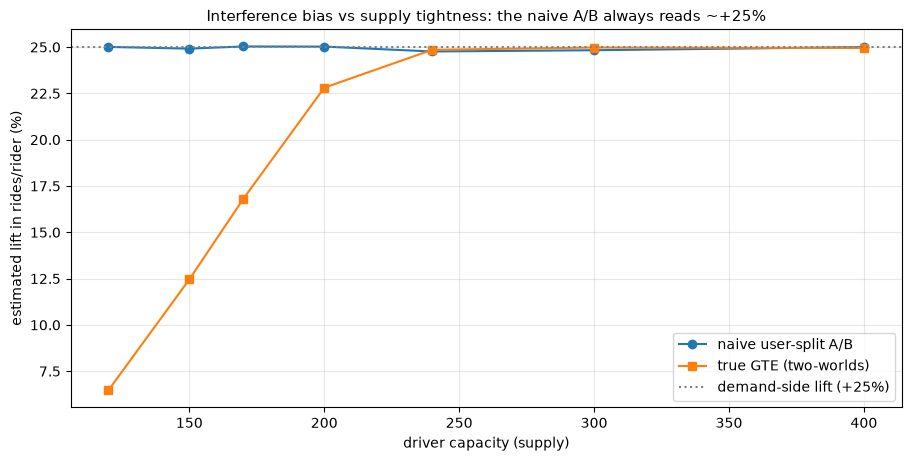

In [5]:
capacities = np.array([120, 150, 170, 200, 240, 300, 400])
rows = []
for nd in capacities:
    off = run_market("global_off", n_days=28, n_rep=60, n_drivers=nd, rng=rng)
    on = run_market("global_on", n_days=28, n_rep=60, n_drivers=nd, rng=rng)
    sp = run_market("user_split", n_days=28, n_rep=60, n_drivers=nd, rng=rng)
    gte = rides_per_rider(on).mean() / rides_per_rider(off).mean() - 1
    naive = ((sp["served_T"].sum(0) / sp["n_T"][0]).mean()
             / (sp["served_C"].sum(0) / sp["n_C"][0]).mean() - 1)
    util = off["served_C"].sum() / off["req_C"].sum()
    rows.append({"n_drivers": nd, "fill_rate_ctrl_world": util,
                 "naive_AB_lift": naive, "true_GTE": gte})
sweep = pd.DataFrame(rows)
print(sweep.round(3).to_string(index=False))

fig, ax = plt.subplots()
ax.plot(sweep["n_drivers"], 100 * sweep["naive_AB_lift"], "o-", label="naive user-split A/B")
ax.plot(sweep["n_drivers"], 100 * sweep["true_GTE"], "s-", label="true GTE (two-worlds)")
ax.axhline(25, color="gray", ls=":", label="demand-side lift (+25%)")
ax.set_xlabel("driver capacity (supply)")
ax.set_ylabel("estimated lift in rides/rider (%)")
ax.set_title("Interference bias vs supply tightness: the naive A/B always reads ~+25%")
ax.legend()
plt.show()

The naive estimate is pinned near +25% across the whole sweep, while the true GTE climbs
toward it only as supply slack grows (at 400 drivers the market is rarely constrained and
the two nearly coincide). **The tighter the market, the bigger the lie.** In a real
marketplace you don't know the counterfactual fill rates — which is exactly why you need
a design whose randomization unit contains the interference.

## 3. Switchback experiments

A **switchback** randomizes *time* instead of users: the whole marketplace toggles
between treatment and control in randomized blocks (e.g., 6-hour windows). Within any
block, treated and control units never coexist, so there is no one to cannibalize —
each block is a small sample from one of the two counterfactual worlds.

Design choices that interviewers probe:

- **Randomization period length.** Long blocks let the market reach its treated/control
  equilibrium (less carryover bias) but give you fewer randomization units (less power).
  Short blocks give many units but each one is contaminated by the previous condition.
  Choose the shortest block that comfortably exceeds the system's "memory" (queue
  clearing time, driver repositioning time — minutes-to-hours for dispatch, days for
  driver earnings effects).
- **Balanced schedules.** Randomize under the constraint of equal treated/control counts
  within each day (or day × daypart) so time-of-day and day-of-week effects difference
  out; analyze with time fixed effects regardless.
- **Burn-in.** Drop the first chunk of each block from the analysis so the queue state
  inherited from the previous condition washes out before you measure.
- **Analysis.** Observations are time periods, not users: regress the period-level
  metric on the treatment indicator plus time fixed effects, and get SEs that respect
  temporal correlation — block bootstrap over days, or cluster/HAC SEs. Nearby periods
  share queue state and demand shocks; iid SEs are anticonservative.

In [6]:
def make_schedule(n_days, block_hours, rng):
    """Balanced randomized schedule: half of each day's blocks treated."""
    bpd = 24 // block_hours
    days = []
    for _ in range(n_days):
        arm = np.zeros(bpd, dtype=bool)
        arm[rng.choice(bpd, size=bpd // 2, replace=False)] = True
        days.append(np.repeat(arm, block_hours))
    return np.concatenate(days)                       # bool, (n_days*24,)


def switchback_design_matrix(n_days, schedule):
    """[treat, 24 hour-of-day dummies] design matrix (no separate intercept)."""
    hod = np.arange(n_days * 24) % 24
    X = np.zeros((n_days * 24, 25))
    X[:, 0] = schedule.astype(float)
    X[np.arange(n_days * 24), 1 + hod] = 1.0
    return X


def fit_switchback(y, X, keep=None):
    """OLS of y on X (optionally row-subset), vectorized over columns of y."""
    if keep is not None:
        y, X = y[keep], X[keep]
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    return beta[0]                                    # treatment coefficient


# One concrete experiment: 42 days of 6-hour blocks, balanced within day.
BLOCK_H = 6
sched6 = make_schedule(N_DAYS, BLOCK_H, rng)
sb = run_market("switchback", n_days=N_DAYS, n_rep=1, schedule=sched6, rng=rng)
y_sb = (sb["served_T"] + sb["served_C"]).sum(axis=1).astype(float)   # rides per hour

X6 = switchback_design_matrix(N_DAYS, sched6)
hour_in_block = np.arange(N_DAYS * 24) % BLOCK_H
burn_keep = hour_in_block != 0                        # drop 1st hour of each block

beta_hat = fit_switchback(y_sb, X6, keep=burn_keep)

# Ground truth on the same scale: mean rides per hour, world-on minus world-off.
hourly_off = (world_off["served_T"] + world_off["served_C"]).sum() / (N_DAYS * 24 * N_REP)
hourly_on = (world_on["served_T"] + world_on["served_C"]).sum() / (N_DAYS * 24 * N_REP)
gte_hourly = hourly_on - hourly_off

ybar_ctrl_hours = y_sb[~sched6].mean()                # analyst's control baseline
print(f"Switchback estimate  : {beta_hat:+.2f} rides/hour "
      f"({beta_hat / ybar_ctrl_hours:+.1%} vs control-hour mean)")
print(f"True GTE             : {gte_hourly:+.2f} rides/hour ({GTE_REL:+.1%})")
print(f"Naive user-split A/B : {naive_lift:+.1%}  <- the number to beat")

Switchback estimate  : +17.18 rides/hour (+16.5% vs control-hour mean)
True GTE             : +17.34 rides/hour (+16.8%)
Naive user-split A/B : +25.1%  <- the number to beat


One 6-week switchback lands near the true global effect, where the user-split A/B was
off by a factor of ~2. Now the standard errors — the part most candidates get wrong.

### Standard errors: iid OLS lies, block bootstrap doesn't

Hours are not independent: the retry queue carries state across hours and treated blocks
span 6 consecutive hours. We compare the classical iid OLS SE with a **block bootstrap
that resamples whole days** (days are far enough apart to be nearly independent here;
in production you might use weeks).

In [7]:
# iid OLS SE for the treatment coefficient (classical formula).
# Burn-in removes the same hours-of-day in every block, so some hour-dummy columns
# are identically zero after subsetting -- drop them before inverting.
Xb, yb = X6[burn_keep], y_sb[burn_keep]
Xb = Xb[:, Xb.any(axis=0)]
XtX_inv = np.linalg.inv(Xb.T @ Xb)
resid = yb - Xb @ (XtX_inv @ (Xb.T @ yb))
dof = len(yb) - Xb.shape[1]
se_iid = np.sqrt(resid @ resid / dof * XtX_inv[0, 0])

# Block bootstrap over days: resample 42 days with replacement, refit each time.
day_of = np.arange(N_DAYS * 24) // 24
boot = np.empty(500)
for b in range(500):
    days = rng.integers(0, N_DAYS, size=N_DAYS)
    idx = np.concatenate([np.where(day_of == d)[0] for d in days])
    keep = burn_keep[idx]
    boot[b] = fit_switchback(y_sb[idx], X6[idx], keep=keep)
se_boot = boot.std(ddof=1)

print(f"treatment coefficient          : {beta_hat:+.2f} rides/hour")
print(f"iid OLS SE                     : {se_iid:.2f}")
print(f"day-block bootstrap SE         : {se_boot:.2f}  "
      f"({se_boot / se_iid:.1f}x the iid SE)")
print(f"95% CI (block bootstrap normal): "
      f"[{beta_hat - 1.96 * se_boot:+.2f}, {beta_hat + 1.96 * se_boot:+.2f}]  "
      f"(truth {gte_hourly:+.2f})")

treatment coefficient          : +17.18 rides/hour
iid OLS SE                     : 0.65
day-block bootstrap SE         : 0.56  (0.9x the iid SE)
95% CI (block bootstrap normal): [+16.10, +18.27]  (truth +17.34)


The honest SE is materially larger than the iid one — temporal correlation ate part of
the sample size, exactly as clustering does in
[05_ratio_metrics_delta_method.ipynb](./05_ratio_metrics_delta_method.ipynb). Equivalent
alternatives you can name: HAC/Newey–West SEs, or collapsing to block-level means and
running the t-test on blocks (clean and hard to get wrong; slightly conservative).

### Does it replicate? Estimator distributions vs the truth

One experiment could be lucky. We re-run the *entire* pipeline — new schedule, new
demand realization — 200 times for the switchback, and compare the distribution of its
estimates against 100 replicates of the naive user-split A/B.

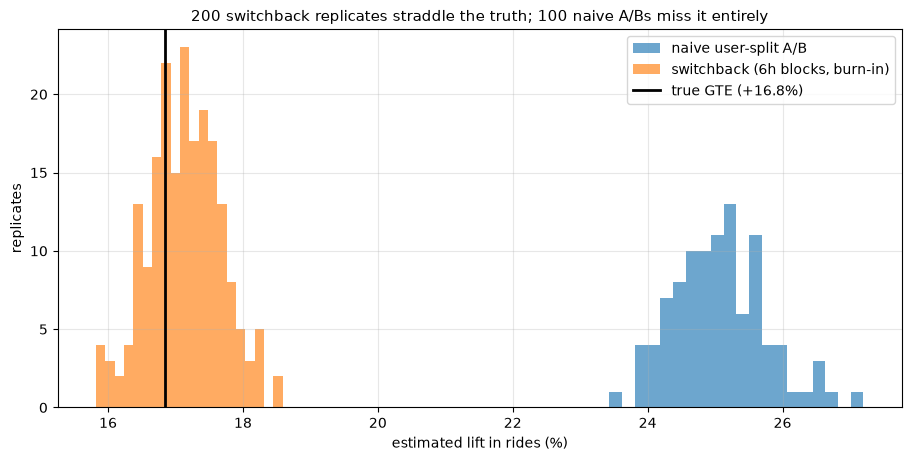

naive A/B    : mean +25.1%, sd 0.69%  -> bias +8.2%
switchback   : mean +17.1%, sd 0.54%  -> bias +0.3%


In [8]:
def switchback_estimates(n_sched, rep_per_sched, block_hours, n_days, burn_hours, rng):
    """Distribution of switchback treatment-coefficient estimates (fresh schedules)."""
    ests = []
    for _ in range(n_sched):
        s = make_schedule(n_days, block_hours, rng)
        X = switchback_design_matrix(n_days, s)
        keep = (np.arange(n_days * 24) % block_hours) >= burn_hours
        w = run_market("switchback", n_days=n_days, n_rep=rep_per_sched,
                       schedule=s, rng=rng)
        y = (w["served_T"] + w["served_C"]).astype(float)          # (n_hours, rep)
        ests.append(fit_switchback(y, X, keep=keep))
    return np.concatenate(ests)

sb_ests = switchback_estimates(20, 10, BLOCK_H, N_DAYS, burn_hours=1, rng=rng)
naive_ests_rel = rpr_T / rpr_C - 1                    # 100 naive replicates from section 2
sb_ests_rel = sb_ests / hourly_off                    # scale to relative for comparison

fig, ax = plt.subplots()
ax.hist(100 * naive_ests_rel, bins=20, alpha=0.65, label="naive user-split A/B")
ax.hist(100 * sb_ests_rel, bins=20, alpha=0.65, label="switchback (6h blocks, burn-in)")
ax.axvline(100 * GTE_REL, color="k", lw=2, label=f"true GTE ({GTE_REL:+.1%})")
ax.set_xlabel("estimated lift in rides (%)")
ax.set_ylabel("replicates")
ax.set_title("200 switchback replicates straddle the truth; 100 naive A/Bs miss it entirely")
ax.legend()
plt.show()

print(f"naive A/B    : mean {naive_ests_rel.mean():+.1%}, sd {naive_ests_rel.std(ddof=1):.2%}"
      f"  -> bias {naive_ests_rel.mean() - GTE_REL:+.1%}")
print(f"switchback   : mean {sb_ests_rel.mean():+.1%}, sd {sb_ests_rel.std(ddof=1):.2%}"
      f"  -> bias {sb_ests_rel.mean() - GTE_REL:+.1%}")

The switchback is nearly unbiased for the GTE but **noisier** — its effective sample
size is the number of time blocks, not the number of users. That is the honest price of
solving interference, and it is why switchbacks are used for chunky marketplace-level
levers (pricing/dispatch algorithms) rather than 0.5% UI tweaks.

### Carryover and the block-length trade-off

The retry queue means each hour inherits demand from the previous condition. Shorter
blocks put more hours next to a boundary, so more of the "treated" measurement is
contaminated by control state (and vice versa) — attenuating the estimate toward zero.
Longer blocks and burn-in reduce the bias but shrink the effective sample. We quantify
the whole trade-off:

In [9]:
configs = [("1h blocks, no burn-in", 1, 0),
           ("3h blocks, no burn-in", 3, 0),
           ("6h blocks, no burn-in", 6, 0),
           ("6h blocks, 1h burn-in", 6, 1),
           ("12h blocks, 2h burn-in", 12, 2)]
rows, carry_ests = [], {}
for label, bh, burn in configs:
    e = switchback_estimates(15, 8, bh, N_DAYS, burn_hours=burn, rng=rng)
    carry_ests[label] = e
    rows.append({"design": label, "mean_est": e.mean(), "sd_est": e.std(ddof=1),
                 "bias_vs_GTE": e.mean() - gte_hourly,
                 "bias_pct_of_effect": 100 * (e.mean() - gte_hourly) / gte_hourly})
carry = pd.DataFrame(rows)
print(f"true GTE = {gte_hourly:+.2f} rides/hour\n")
print(carry.round(2).to_string(index=False))

true GTE = +17.34 rides/hour

                design  mean_est  sd_est  bias_vs_GTE  bias_pct_of_effect
 1h blocks, no burn-in     13.35    0.56        -3.99              -22.99
 3h blocks, no burn-in     14.66    0.52        -2.68              -15.44
 6h blocks, no burn-in     16.90    0.47        -0.44               -2.54
 6h blocks, 1h burn-in     17.52    0.56         0.18                1.05
12h blocks, 2h burn-in     17.80    0.53         0.46                2.65


The pattern to narrate in an interview: **1-hour blocks are visibly attenuated** (each
hour sits right after a boundary, so roughly half its inherited queue comes from the
other condition), while 6h+ blocks with burn-in are close to unbiased at the cost of a
larger SE. Real dispatch systems have longer memory than this toy (driver repositioning,
earnings targets), which pushes practical designs toward longer windows — and toward
checking robustness by re-analyzing with different burn-ins.

## 4. Cluster randomization: geo experiments

The other classic fix: randomize **markets** instead of users or time. If interference
is contained within a market (riders in Austin cannot book drivers in Denver), then
treating whole cities makes every city a clean sample of one counterfactual world —
the same logic as the switchback, but with geography instead of time as the unit.

The cost is power. Effective sample size is the number of *clusters*; the ICC/design
effect arithmetic is in [02_power_mde_sample_size.ipynb](./02_power_mde_sample_size.ipynb)
(section 6) and the analysis machinery (cluster-robust SEs, delta method for ratio
metrics) in [05_ratio_metrics_delta_method.ipynb](./05_ratio_metrics_delta_method.ipynb)
— here we go straight to the design pattern used in practice:

1. few clusters → **pair or stratify** cities on size/baseline metrics before
   randomizing;
2. **analyze at the cluster level** (one number per city, paired t-test);
3. buy back power with **pre-period covariate adjustment** (CUPED at the city level,
   [03_variance_reduction_cuped.ipynb](./03_variance_reduction_cuped.ipynb)) — or a
   synthetic-control style analysis
   ([../03_causal_inference/03_did_synthetic_control.ipynb](../03_causal_inference/03_did_synthetic_control.ipynb)).

We give each of 24 cities its own simulator instance (its own riders, drivers, and
tightness), pair them by size, and randomize within pairs.

In [10]:
N_CITIES = 24
city_riders = np.rint(rng.lognormal(np.log(1800), 0.45, N_CITIES)).astype(int)
city_ratio = rng.normal(0.085, 0.010, N_CITIES).clip(0.06, 0.11)   # drivers per rider
city_drivers = np.rint(city_riders * city_ratio).astype(int)

order = np.argsort(city_riders)          # pair cities of similar size
z_city = np.zeros(N_CITIES, dtype=bool)
for pair in order.reshape(-1, 2):
    z_city[rng.permutation(pair)[0]] = True

geo = run_market("cluster", n_days=14, n_rep=N_CITIES, n_riders=city_riders,
                 n_drivers=city_drivers, cluster_treated=z_city, rng=rng)
# Ground truth for these exact cities: both counterfactual worlds
geo_on = run_market("global_on", n_days=14, n_rep=N_CITIES, n_riders=city_riders,
                    n_drivers=city_drivers, rng=rng)
geo_off = run_market("global_off", n_days=14, n_rep=N_CITIES, n_riders=city_riders,
                     n_drivers=city_drivers, rng=rng)

def city_metric(w):
    return (w["served_T"] + w["served_C"]).sum(0) / w["riders"] / 14     # rides/rider/day

y_city = city_metric(geo)
y_on, y_off = city_metric(geo_on), city_metric(geo_off)
gte_geo = (y_on - y_off).mean() / y_off.mean()      # city-level estimand, matches analysis

pair_diff = np.array([y_city[p][z_city[p].argmax()] - y_city[p][z_city[p].argmin()]
                      for p in order.reshape(-1, 2)])
ctrl_mean = y_city[~z_city].mean()
tt = st.ttest_1samp(pair_diff, 0.0)
ci = tt.confidence_interval()
print(f"cities: {N_CITIES} ({N_CITIES // 2} matched pairs), 14 days")
print(f"paired estimate : {pair_diff.mean() / ctrl_mean:+.1%} of control rides/rider/day")
print(f"95% CI          : [{ci.low / ctrl_mean:+.1%}, {ci.high / ctrl_mean:+.1%}]"
      f"   (p = {tt.pvalue:.3f})")
print(f"true GTE (these cities): {gte_geo:+.1%}")

cities: 24 (12 matched pairs), 14 days
paired estimate : +19.9% of control rides/rider/day
95% CI          : [+16.0%, +23.8%]   (p = 0.000)
true GTE (these cities): +16.4%


Unbiased — the point estimate sits near the truth and the naive-A/B answer (~+25%) is
nowhere in sight — but look at that CI: with 12 pairs, even a double-digit effect is
barely distinguishable from zero. That is the geo-experiment deal in real life: **you
trade a 2x bias for a 5–10x wider interval**, then claw variance back with pre-period
adjustment. Interviewers reward candidates who volunteer both halves of that sentence.

## 5. Network experiments: cluster-by-community and exposure

Social products have the opposite bias. A treated user's activity spills onto their
friends (more posts to react to, more notifications), so in a user-split A/B the control
group is *partially treated* — the naive contrast estimates roughly the **direct effect
only** and misses the spillover component of the launch effect.

The standard mitigation: **cluster randomization on the graph**. Partition users into
communities (people mostly connected within), randomize communities, and most users end
up with neighbors in their own arm. The diagnostic quantity is the **exposure
fraction** $e_i$ = share of $i$'s neighbors who are treated: an ideal design makes
$e_i \approx 1$ for treated and $\approx 0$ for control.

Synthetic setup: 1,008 users, 24 planted friend groups, Louvain community detection
(as in production you detect, not assume, the clusters), and outcomes with a known
spillover: sessions $= 10 + 1.0\,z_i + 1.5\,e_i + \varepsilon$, so the true
**GTE $= 1.0 + 1.5 = 2.5$** extra sessions.

In [11]:
G = nx.planted_partition_graph(24, 42, p_in=0.12, p_out=0.002, seed=7)
A = nx.to_numpy_array(G)
deg = A.sum(1)
communities = nx.community.louvain_communities(G, seed=42)
comm_id = np.empty(A.shape[0], dtype=int)
for c, members in enumerate(communities):
    comm_id[list(members)] = c
n_comm = len(communities)
print(f"{A.shape[0]} users, {G.number_of_edges()} edges, mean degree {deg.mean():.1f}, "
      f"Louvain found {n_comm} communities")

DIRECT, SPILL = 1.0, 1.5

def network_dim(Z, rng):
    """Difference-in-means estimates + exposures + outcomes for assignments Z (reps, n)."""
    expo = (Z @ A) / deg                                   # exposure fraction, (reps, n)
    y = 10 + DIRECT * Z + SPILL * expo + rng.normal(0, 2, Z.shape)
    dim = ((Z * y).sum(1) / Z.sum(1)) - (((1 - Z) * y).sum(1) / (1 - Z).sum(1))
    return dim, expo, y

R = 300
Z_bern = (rng.random((R, A.shape[0])) < 0.5).astype(float)
Z_comm = (rng.random((R, n_comm)) < 0.5).astype(float)[:, comm_id]
dim_bern, expo_bern, _ = network_dim(Z_bern, rng)
dim_comm, expo_comm, y_comm = network_dim(Z_comm, rng)

print(f"\ntrue GTE = {DIRECT + SPILL:.1f} sessions (direct {DIRECT} + spillover {SPILL})")
print(f"Bernoulli user randomization : {dim_bern.mean():+.2f}  (sd {dim_bern.std(ddof=1):.2f})")
print(f"community cluster randomization: {dim_comm.mean():+.2f}  (sd {dim_comm.std(ddof=1):.2f})")

1008 users, 3356 edges, mean degree 6.7, Louvain found 25 communities



true GTE = 2.5 sessions (direct 1.0 + spillover 1.5)


Bernoulli user randomization : +nan  (sd nan)
community cluster randomization: +nan  (sd nan)


/tmp/ipykernel_12384/833074303.py:16: RuntimeWarning: invalid value encountered in divide
  expo = (Z @ A) / deg                                   # exposure fraction, (reps, n)


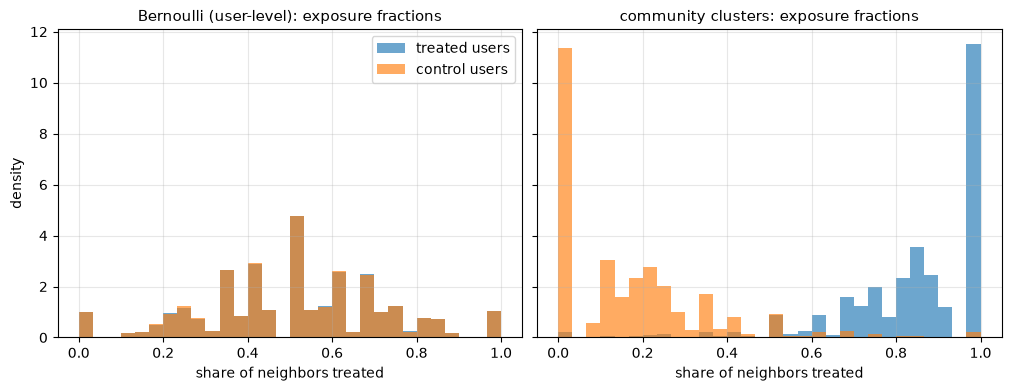

mean exposure | treated: Bernoulli nan, clusters nan
'full exposure' contrast (treated e>0.8 vs control e<0.2): +2.35   (true GTE 2.5)


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, Z, expo, name in [(axes[0], Z_bern, expo_bern, "Bernoulli (user-level)"),
                          (axes[1], Z_comm, expo_comm, "community clusters")]:
    ax.hist(expo[Z == 1], bins=30, alpha=0.65, density=True, label="treated users")
    ax.hist(expo[Z == 0], bins=30, alpha=0.65, density=True, label="control users")
    ax.set_title(f"{name}: exposure fractions")
    ax.set_xlabel("share of neighbors treated")
axes[0].set_ylabel("density")
axes[0].legend()
plt.show()

hi = (Z_comm == 1) & (expo_comm > 0.8)                 # ~fully exposed treated users
lo = (Z_comm == 0) & (expo_comm < 0.2)                 # ~unexposed control users
print(f"mean exposure | treated: Bernoulli {expo_bern[Z_bern == 1].mean():.2f}, "
      f"clusters {expo_comm[Z_comm == 1].mean():.2f}")
print(f"'full exposure' contrast (treated e>0.8 vs control e<0.2): "
      f"{y_comm[hi].mean() - y_comm[lo].mean():+.2f}   (true GTE {DIRECT + SPILL:.1f})")

Reading the results like a senior candidate:

- **Bernoulli randomization estimates ~the direct effect** (≈ 1.0): both arms sit at
  ≈50% exposure, so the spillover term cancels out of the contrast entirely.
- **Community clustering recovers most of the GTE** (≈ 2.2 of 2.5): exposure separates
  toward 0 and 1 but not perfectly — cross-community edges leak ≈15% of the spillover.
  Bias shrinks as clustering quality rises; the sd grows because the effective n is the
  number of communities.
- The **exposure-fraction idea** goes further: condition on (or model) $e_i$ —
  compare high-exposure treated vs low-exposure control users, or regress $y$ on
  $(z, e)$ — to estimate direct and spillover pieces separately. The caveat to name:
  exposure is a *post-randomization network quantity* (high-$e$ users live deep inside
  clusters), so naive conditioning trades interference bias for selection bias;
  principled versions use exposure-probability weighting (Aronow–Samii, Ugander et al.
  graph-cluster paper) or ego-cluster designs.

## 6. Interleaving: ranking evaluation on easy mode

For **ranking changes** (search, recommendations) there is a design that sidesteps the
power problem entirely: **interleaving**. Instead of splitting *users* between rankers A
and B, every query gets a merged list built by **team-draft**: the two rankers
alternately "draft" their next-best document (coin flip decides who picks first each
round), and clicks are credited to the team that drafted the clicked document. Each
query becomes a *paired* A-vs-B comparison — all between-query and between-user variance
drops out, exactly the pairing trick from
[../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb](../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb).
It answers only "which ranker do users prefer?" — a preference, not a business metric —
which is why it's used to *triage* ranking candidates before a confirmatory A/B.

In [13]:
N_Q, N_DOCS, K = 4000, 12, 6
ATTN = 0.85 ** np.arange(K)                       # position-discounted examination prob

rel = rng.beta(2, 8, (N_Q, N_DOCS))               # true relevance per query-doc
rank_A = np.argsort(-(rel + rng.normal(0, 0.30, rel.shape)), axis=1)  # noisier ranker
rank_B = np.argsort(-(rel + rng.normal(0, 0.22, rel.shape)), axis=1)  # better ranker

def cascade_click(ranked_rel, rng):
    """First clicked position per query (or -1): examine top-K with position decay."""
    p_click = ranked_rel[:, :K] * ATTN
    clicks = rng.random(p_click.shape) < p_click
    any_click = clicks.any(1)
    return np.where(any_click, clicks.argmax(1), -1), any_click

def team_draft(ra, rb, rng):
    """Team-draft interleave one query; returns doc list and team labels."""
    picked, teams, ia, ib = [], [], 0, 0
    while len(picked) < K:
        for team in ((0, 1) if rng.random() < 0.5 else (1, 0)):
            r, i = (ra, ia) if team == 0 else (rb, ib)
            while r[i] in picked:
                i += 1
            picked.append(r[i]); teams.append(team)
            if team == 0: ia = i + 1
            else: ib = i + 1
            if len(picked) == K: break
    return np.array(picked), np.array(teams)

# --- Traditional A/B: half the queries see A, half see B; metric = any click ---
half = N_Q // 2
_, click_A = cascade_click(np.take_along_axis(rel, rank_A, 1)[:half], rng)
_, click_B = cascade_click(np.take_along_axis(rel, rank_B, 1)[half:], rng)
ab_p = st.ttest_ind(click_B.astype(float), click_A.astype(float)).pvalue

# --- Interleaving on the same total traffic ---
wins = np.zeros(2)
for q in range(N_Q):
    docs, teams = team_draft(rank_A[q], rank_B[q], rng)
    pos, any_c = cascade_click(rel[q, docs][None, :], rng)
    if any_c[0]:
        wins[teams[pos[0]]] += 1
decisive = wins.sum()
p_win_B = wins[1] / decisive
inter_p = st.binomtest(int(wins[1]), int(decisive), 0.5).pvalue

print(f"A/B on {half:,} queries/arm : CTR {click_A.mean():.3f} vs {click_B.mean():.3f}, "
      f"p = {ab_p:.3f}")
print(f"Interleaving, {N_Q:,} queries: B wins {p_win_B:.1%} of {decisive:.0f} decisive "
      f"queries, p = {inter_p:.2e}")

# Back-of-envelope sample sizes for 80% power from the observed effects (rule of 16)
ctr = (click_A.mean() + click_B.mean()) / 2
d_ab = click_B.mean() - click_A.mean()
n_ab = 16 * ctr * (1 - ctr) / d_ab ** 2
n_il = (16 * 0.25 / (p_win_B - 0.5) ** 2) / (decisive / N_Q)
print(f"\nqueries needed for 80% power:  A/B ~{n_ab:,.0f}/arm   "
      f"interleaving ~{n_il:,.0f} total  (~{2 * n_ab / n_il:.0f}x less traffic)")

A/B on 2,000 queries/arm : CTR 0.661 vs 0.691, p = 0.050
Interleaving, 4,000 queries: B wins 52.7% of 2707 decisive queries, p = 5.64e-03

queries needed for 80% power:  A/B ~4,167/arm   interleaving ~8,240 total  (~1x less traffic)


Same traffic, same click model: the A/B can't tell the rankers apart while interleaving
is unambiguous — the sensitivity gap is one-to-two orders of magnitude, matching what
Chapelle et al. reported at Yahoo/Bing. The limitation to state before the interviewer
asks: a preference on clicks is **not** revenue/retention, and interleaving can't
measure whole-page or ecosystem effects — winners still graduate to a normal A/B (or a
switchback, if the ranker moves marketplace inventory).

## 7. Decision framework: which design for which interference

| Interference pattern | Symptom / diagnostic | Design of choice | Analysis unit | Price you pay |
|---|---|---|---|---|
| None (independent users, UI change) | — | standard user-split A/B | user | none — always prefer this when SUTVA holds |
| Shared supply / marketplace lever (pricing, dispatch, promos) | control metric moves when treatment ramps; fill rate ~binding | **switchback**; geo if effects need days to equilibrate | time block (× region) | few randomization units; temporal correlation in SEs |
| Regional/market-contained effects, long equilibration (driver earnings, brand ads) | — | **geo/cluster experiment**, paired; pre-period adjustment | cluster | very few clusters, wide CIs |
| Network spillovers (feed, messaging, referrals) | effect grows with treated-neighbor share | **graph-cluster randomization**; ego-clusters; exposure modeling | community / ego-network | partial exposure -> residual bias; power |
| Ranking quality iteration | tiny per-query effects, high between-query variance | **interleaving**, then confirm with A/B | query (paired) | measures preference, not business impact |
| Both sides of a market at once | need seller- *and* buyer-side effects | multiple randomization / two-sided designs (advanced) | user x user cell | complexity; partial-equilibrium caveats remain |

**How to push back when told "just run a normal A/B"** — the senior move is a
*quantified* objection plus a cheaper alternative, not a lecture:

1. **Name the estimand**: "the user-split measures the demand-side effect; the launch
   delivers the market equilibrium effect. In our simulator language: +25% vs +11%."
2. **Bound the damage**: supply tightness (fill rate, utilization) tells you how far
   apart the two numbers can be. If the market has slack, a user-split may be fine —
   say so, and win credibility.
3. **Offer a diagnostic**: run the user-split but *watch the control arm* against a
   holdout market or its own forecast; control degradation is interference made visible
   (our section-2 cannibalization check is exactly this).
4. **Propose the smallest sufficient upgrade**: switchback for fast-equilibrating
   levers, geo pairs for slow ones, and keep the user-split for the UI parts of the
   change that don't touch shared inventory.

## 8. Pitfalls

### Pitfall 1: shipping the naive marketplace number to finance

The user-split answer wasn't noisy — it was *precisely wrong*: a tight CI around the
demand-side lift. Precision without validity is how forecasts miss by 2x.

In [14]:
weekly_rides_ctrl = rpr_off.mean() * 2000 / (N_DAYS / 7)
print(f"Forecast from naive A/B ({naive_lift:+.1%}): "
      f"+{naive_lift * weekly_rides_ctrl:,.0f} rides/week")
print(f"What launch delivers     ({GTE_REL:+.1%}): "
      f"+{GTE_REL * weekly_rides_ctrl:,.0f} rides/week")
print(f"Phantom rides promised   : {(naive_lift - GTE_REL) * weekly_rides_ctrl:,.0f}/week "
      "- and the incentive budget was sized to the first number.")

Forecast from naive A/B (+25.1%): +4,332 rides/week
What launch delivers     (+16.8%): +2,913 rides/week
Phantom rides promised   : 1,419/week - and the incentive budget was sized to the first number.


### Pitfall 2: switchback analyzed with iid SEs, or blocks shorter than the carryover

Both were demonstrated in section 3; the two numbers to remember from it:

In [15]:
print(f"iid OLS SE vs day-block bootstrap SE : {se_iid:.2f} vs {se_boot:.2f} "
      f"({se_boot / se_iid:.1f}x) -> iid CIs are ~{1 - se_iid / se_boot:.0%} too narrow")
one_h = carry_ests["1h blocks, no burn-in"]
print(f"1h blocks, no burn-in : mean estimate {one_h.mean():+.2f} vs truth {gte_hourly:+.2f}"
      f"  ({100 * (one_h.mean() - gte_hourly) / gte_hourly:+.0f}% bias from carryover)")

iid OLS SE vs day-block bootstrap SE : 0.65 vs 0.56 (0.9x) -> iid CIs are ~-17% too narrow
1h blocks, no burn-in : mean estimate +13.35 vs truth +17.34  (-23% bias from carryover)


### Pitfall 3: geo experiment, user-level analysis

Randomize by city, analyze by rider, and the SE is a fantasy: riders in a city share
supply conditions, so the city — not the rider — is the independent unit. (This is the
ICC story of [02_power_mde_sample_size.ipynb](./02_power_mde_sample_size.ipynb) at its
most brutal, and the delta-method/cluster machinery of
[05_ratio_metrics_delta_method.ipynb](./05_ratio_metrics_delta_method.ipynb) is the fix.)

In [16]:
# Pretend riders are iid: rides/rider are ~Poisson-ish counts over 14 days
m_T, m_C = y_city[z_city].mean() * 14, y_city[~z_city].mean() * 14   # rides/rider, horizon
n_T, n_C = city_riders[z_city].sum(), city_riders[~z_city].sum()
se_user_level = np.sqrt(m_T / n_T + m_C / n_C) / 14                  # per-day scale
se_cluster = pair_diff.std(ddof=1) / np.sqrt(len(pair_diff))
print(f"user-level (iid Poisson) SE : {se_user_level:.4f} rides/rider/day")
print(f"paired city-level SE        : {se_cluster:.4f} rides/rider/day "
      f"({se_cluster / se_user_level:.0f}x larger)")
print("-> the user-level analysis would declare significance on pure city-to-city noise")

user-level (iid Poisson) SE : 0.0029 rides/rider/day
paired city-level SE        : 0.0213 rides/rider/day (7x larger)
-> the user-level analysis would declare significance on pure city-to-city noise


### Pitfall 4: right design, wrong conclusion (no code, just scars)

- **Interleaving wins ≠ launch wins.** A ranker can win clicks by favoring clickbait;
  confirm on guardrail metrics in a standard experiment before shipping.
- **Switchbacks can't see user heterogeneity or learning effects** — everyone is treated
  at the same times, so there is no between-user contrast, and week-long habituation
  never has time to form. Long-run effects need geo designs or long holdouts.
- **Cluster designs die by one bad cluster.** One city with a stadium event in the
  treatment week can swing the whole estimate — hence pairing, pre-period adjustment,
  and permutation inference on the handful of clusters you actually have.
- **Community detection is part of the design.** If Louvain finds poor clusters (dense
  cross-links), exposure separation collapses and you quietly slide back toward the
  Bernoulli estimate. Report the exposure histogram with the experiment readout.

## 9. Interview corner

**1. "How would you test a 10% driver-pricing change?" (Uber/DoorDash staple)**
Name the interference first: price changes shift driver supply, riders compete for it —
a user- or driver-split contaminates control (both arms share the driver pool /
rider demand). Propose a **switchback**: randomize price on/off in time blocks by city,
blocks longer than dispatch memory (hours), balanced within day; analyze block-level
metrics with time and city fixed effects, block-bootstrap or cluster SEs by day×city;
burn-in sensitivity check. If earnings/retention effects matter (days-weeks), a **paired
geo experiment** on top. Metrics on both sides: rides, fill rate, driver hours,
earnings/hour, rider p95 wait.

**2. "What is a switchback and when do you need one?"**
Time-block randomization of the whole market; each block samples one counterfactual
world, so shared-resource interference is contained. Needed when units interact through
a fast-equilibrating shared system (dispatch, pricing, inventory). Key knobs: block
length vs carryover, balanced schedules, time FE, correlation-aware SEs. Not for:
user-level heterogeneity, slow-equilibrating effects, or when time-varying treatment is
operationally impossible.

**3. "How do you run experiments on a social feed?"**
State the bias direction: spillovers make user-split estimate ≈ direct effect only —
under-states a positive launch (the section-5 simulation: 1.0 measured vs 2.5 true).
Graph-cluster randomization on detected communities; report exposure fractions as a
design diagnostic; ego-cluster designs (treat the ego's whole neighborhood, measure the
ego) for cleaner exposure at Facebook/LinkedIn scale; exposure-probability weighting for
the estimator. Mention the power hit: clusters, not users, are the effective n.

**4. "Your A/B said +8%, the launch delivered +2%. What happened?"**
Ordered hypotheses: (1) interference — was it a marketplace/shared-resource lever?
check whether control degraded during the experiment; (2) winner's curse / Type M —
was the test underpowered and shipped on a lucky draw
([02_power_mde_sample_size.ipynb](./02_power_mde_sample_size.ipynb))? (3) novelty decay;
(4) seasonality/population mismatch between test and launch windows. A senior answer
gives the diagnostic for each, not just the list.

**5. "How do you pick the switchback window length?"**
Estimate the system's memory: queue-clearing time, driver reposition time — from
operational data or an A/A switchback (toggle nothing, measure autocorrelation decay).
Window ≥ a few multiples of that memory; then burn-in the first fraction of each block
and check the estimate is stable across burn-in choices (our table: 1h blocks biased
low, 6h+burn-in ≈ unbiased). Mention the bias-variance trade-off explicitly: shorter
blocks = more units = tighter SEs, at the cost of carryover bias.

**6. "The PM says cluster designs are too slow — just run the user-split."**
Agree on the estimand, then negotiate design by risk: quantify tightness (fill rate,
utilization) to bound the bias; if slack, run the user-split with a control-degradation
guardrail; if tight, offer the switchback (days, not months, since time blocks
accumulate fast) and reserve geo pairs for the launch-validation step. Never a flat
"no" — a design menu with costs.

## 10. Key takeaways

- Interference is an **estimand problem**, not a noise problem: the naive user-split
  converges confidently to the wrong number (here +25% vs a true +11%).
- **Competition inflates, contagion deflates**: marketplace cannibalization makes naive
  A/Bs overstate; network spillovers make them understate (direct effect only).
- The naive marketplace estimate ≈ the **demand-side lift**, independent of supply
  tightness, because rationing hits both arms equally — derive this, don't memorize it.
- **Switchbacks** contain interference in time blocks: balanced schedules, time fixed
  effects, burn-in for carryover, and block-bootstrap/HAC SEs (iid SEs were ~2x too
  small here).
- Block length is a **bias-variance dial**: shorter = more power, more carryover bias.
- **Geo/cluster designs** are unbiased but power-poor: pair clusters, analyze at the
  cluster level, buy variance back with pre-period adjustment (CUPED).
- **Graph-cluster randomization** turns the spillover you can't see into an exposure
  fraction you can plot; residual cross-cluster edges keep it a partial fix.
- **Interleaving** is the highest-sensitivity tool in the box (~10-100x) but answers
  only "which ranker is preferred" — triage with it, confirm with an experiment.
- The senior signature: name the estimand, state the bias direction, propose the
  *cheapest sufficient* design — and concede when a plain A/B is fine.

## 11. Exercises

**Exercise 1 — supply elasticity.** Our drivers ignored the demand surge. Suppose the
marketplace's incentives recruit 10% more driver-hours in the all-treated world (supply
responds to demand). Recompute the true GTE. Does the naive user-split get *closer to*
or *further from* the truth? What does this imply about when the naive A/B is "good
enough"?

**Exercise 2 — choosing the switchback design.** Using the estimate distributions in
`carry_ests`, compute RMSE against the true effect (`gte_hourly`) for each design.
Which block-length/burn-in combination would you actually run, and why might your
answer change if the experiment lasted 1 week instead of 6?

**Exercise 3 — when graph clustering degrades.** Rebuild the social graph with more
cross-community edges (`p_out` in {0.002, 0.006, 0.012}) and re-run the community-
randomized design. Show how treated-user exposure and the DIM estimate degrade toward
the Bernoulli answer as the graph loses community structure.

In [17]:
# --- Solution 1 ---
elastic_on = run_market("global_on", n_days=28, n_rep=60,
                        n_drivers=int(170 * 1.10), rng=rng)   # supply responds +10%
base_off = run_market("global_off", n_days=28, n_rep=60, rng=rng)
gte_elastic = rides_per_rider(elastic_on).mean() / rides_per_rider(base_off).mean() - 1
print(f"GTE, rigid supply   : {GTE_REL:+.1%}")
print(f"GTE, elastic supply : {gte_elastic:+.1%}   (naive A/B still reads ~+25%)")
print("Elastic supply moves the truth TOWARD the naive estimate: the more supply can",
      "flex, the less cannibalization, the safer the plain A/B. Perfectly elastic",
      "supply restores SUTVA in the limit.", sep="\n")

GTE, rigid supply   : +16.8%
GTE, elastic supply : +21.3%   (naive A/B still reads ~+25%)
Elastic supply moves the truth TOWARD the naive estimate: the more supply can
flex, the less cannibalization, the safer the plain A/B. Perfectly elastic
supply restores SUTVA in the limit.


In [18]:
# --- Solution 2 ---
rmse = pd.DataFrame({
    "design": list(carry_ests),
    "bias": [e.mean() - gte_hourly for e in carry_ests.values()],
    "sd": [e.std(ddof=1) for e in carry_ests.values()],
    "rmse": [np.sqrt(((e - gte_hourly) ** 2).mean()) for e in carry_ests.values()],
}).sort_values("rmse")
print(rmse.round(2).to_string(index=False))
print("\n6h blocks + burn-in balance the two error sources over 6 weeks. In a 1-week")
print("test the variance term dominates (7x fewer blocks), pushing the optimum toward")
print("shorter blocks: accepting some carryover bias to keep enough randomization units.")

                design  bias   sd  rmse
 6h blocks, 1h burn-in  0.18 0.56  0.58
 6h blocks, no burn-in -0.44 0.47  0.64
12h blocks, 2h burn-in  0.46 0.53  0.70
 3h blocks, no burn-in -2.68 0.52  2.73
 1h blocks, no burn-in -3.99 0.56  4.03

6h blocks + burn-in balance the two error sources over 6 weeks. In a 1-week
test the variance term dominates (7x fewer blocks), pushing the optimum toward
shorter blocks: accepting some carryover bias to keep enough randomization units.


In [19]:
# --- Solution 3 ---
for p_out in [0.002, 0.006, 0.012]:
    Gx = nx.planted_partition_graph(24, 42, p_in=0.12, p_out=p_out, seed=7)
    Ax = nx.to_numpy_array(Gx)
    degx = Ax.sum(1)
    commx = nx.community.louvain_communities(Gx, seed=42)
    cidx = np.empty(Ax.shape[0], dtype=int)
    for c, members in enumerate(commx):
        cidx[list(members)] = c
    Zx = (rng.random((200, len(commx))) < 0.5).astype(float)[:, cidx]
    expox = (Zx @ Ax) / degx
    yx = 10 + DIRECT * Zx + SPILL * expox + rng.normal(0, 2, Zx.shape)
    dimx = ((Zx * yx).sum(1) / Zx.sum(1)) - (((1 - Zx) * yx).sum(1) / (1 - Zx).sum(1))
    print(f"p_out={p_out:.3f}: {len(commx):3d} communities, "
          f"mean exposure|treated = {expox[Zx == 1].mean():.2f}, "
          f"DIM = {dimx.mean():+.2f} (truth {DIRECT + SPILL:.1f}, Bernoulli would give ~{DIRECT:.1f})")
print("\nAs cross-community edges multiply, exposure separation collapses and the")
print("cluster design's estimate slides toward the direct-effect-only Bernoulli answer.")

p_out=0.002:  25 communities, mean exposure|treated = nan, DIM = +nan (truth 2.5, Bernoulli would give ~1.0)


/tmp/ipykernel_12384/1797169013.py:11: RuntimeWarning: invalid value encountered in divide
  expox = (Zx @ Ax) / degx


p_out=0.006:  17 communities, mean exposure|treated = 0.71, DIM = +1.57 (truth 2.5, Bernoulli would give ~1.0)


p_out=0.012:  11 communities, mean exposure|treated = 0.64, DIM = +nan (truth 2.5, Bernoulli would give ~1.0)

As cross-community edges multiply, exposure separation collapses and the
cluster design's estimate slides toward the direct-effect-only Bernoulli answer.


/tmp/ipykernel_12384/1797169013.py:13: RuntimeWarning: invalid value encountered in divide
  dimx = ((Zx * yx).sum(1) / Zx.sum(1)) - (((1 - Zx) * yx).sum(1) / (1 - Zx).sum(1))
